In [1]:
# 1. SETUP & IMPORTS
import os
import random
import numpy as np
import torch
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Ensure Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# Local directory for dataset
DATA_DIR = "./data/svhn"
if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Environment initialized. Using device: {device}")

Environment initialized. Using device: cpu


Loading SVHN Dataset...


100%|███████████████████████████████████████████████████████████████████████████████| 182M/182M [38:43<00:00, 78.3kB/s]
<local-path>
  order = pd.unique(vector)


Error: num must be an integer with 1 <= num <= 16, not 17


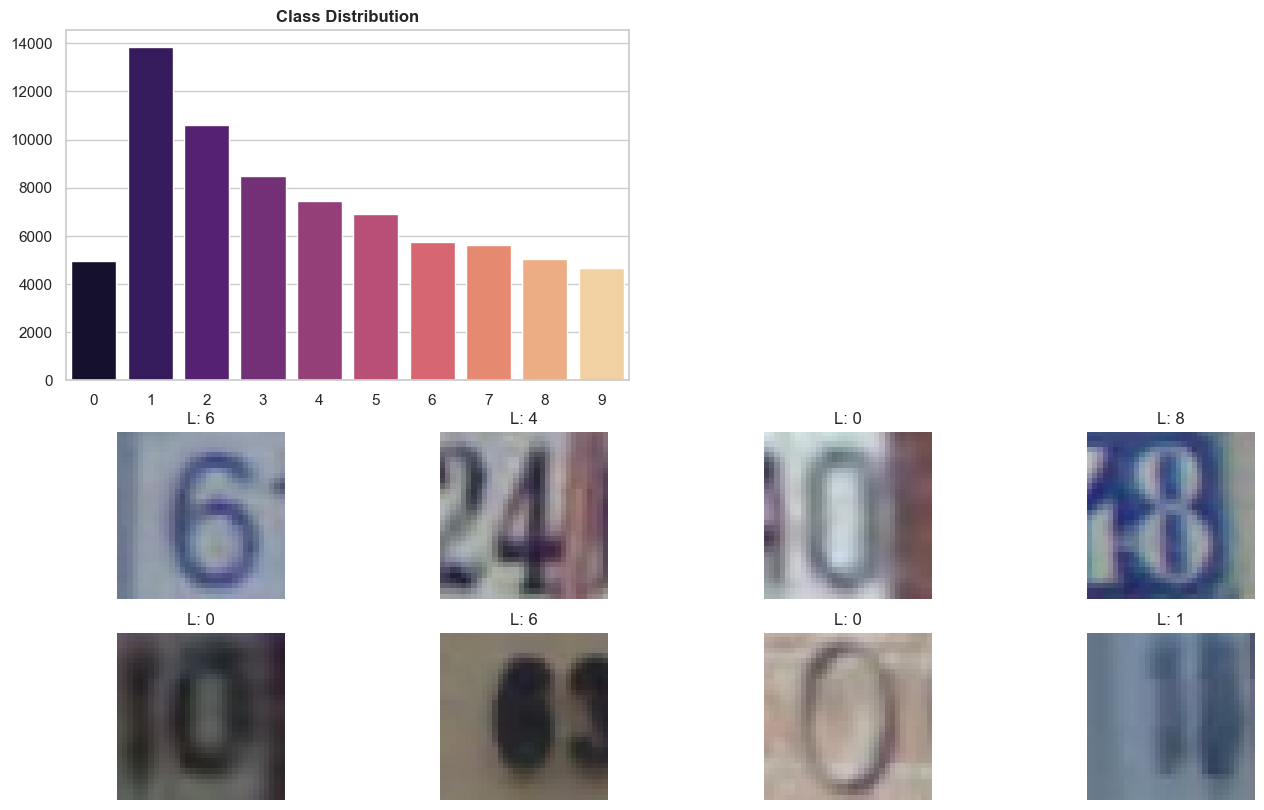

In [3]:
# 2. SVHN DATASET LOADING & VISUALIZATION
try:
    print(f"Loading SVHN Dataset...")
    svhn_train = torchvision.datasets.SVHN(root=DATA_DIR, split='train', download=True)
    labels = svhn_train.labels
    images = svhn_train.data # (N, 3, 32, 32)

    class_names = [str(i) for i in range(10)]
    class_counts = np.bincount(labels)

    sns.set_theme(style="whitegrid")
    fig = plt.figure(figsize=(16, 10))

    # Bar Plot
    ax1 = fig.add_subplot(2, 2, 1)
    sns.barplot(x=class_names, y=class_counts, palette="magma", ax=ax1)
    ax1.set_title("Class Distribution", fontweight='bold')

    # Sample Grid
    ax3 = fig.add_subplot(2, 2, 3)
    ax3.axis('off')
    indices = np.random.choice(len(images), 16, replace=False)
    sample_imgs = np.transpose(images[indices], (0, 2, 3, 1))
    
    for i in range(16):
        plt.subplot(4, 4, i+9) # Positioning in the grid
        plt.imshow(sample_imgs[i])
        plt.title(f"L: {labels[indices[i]]}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error: {e}")

In [23]:
# UPDATED CELL 3: SETUP & DATALOADERS (OPTIMIZED)
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# 64x64 is the "Sweet Spot" for SVHN speed vs accuracy
img_size = 64 

train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.437, 0.443, 0.472], std=[0.198, 0.201, 0.197])
])

test_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.437, 0.443, 0.472], std=[0.198, 0.201, 0.197])
])

# Load Datasets
DATA_DIR = "./svhn_dataset"
svhn_train = datasets.SVHN(root=DATA_DIR, split='train', transform=train_transform, download=True)
svhn_test = datasets.SVHN(root=DATA_DIR, split='test', transform=test_transform, download=True)

# 80/20 Split
train_size = int(0.8 * len(svhn_train))
val_size = len(svhn_train) - train_size
train_dataset, val_dataset = random_split(svhn_train, [train_size, val_size])

# Dataloaders - Using batch_size 128 to speed up training
dataloaders = {
    'train': DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True),
    'val': DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=2, pin_memory=True),
    'test': DataLoader(svhn_test, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)
}

# Criterion with your calculated weights
class_weights = torch.tensor([1.48, 0.52, 0.69, 0.86, 0.98, 1.06, 1.28, 1.31, 1.45, 1.57], dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

print(f"Dataloaders ready at {img_size}x{img_size} resolution.")

100%|████████████████████████████████████████████████████████████████████████████████| 182M/182M [23:48<00:00, 127kB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 64.3M/64.3M [05:09<00:00, 208kB/s]


Dataloaders ready at 64x64 resolution.


In [25]:
import torch
import torch.nn as nn  # <--- This fixes your NameError
from torchvision import models

def get_model(name, variation):
    model = None
    
    # --- MODEL 1: MOBILENET V3 ---
    if name == "mobilenet":
        if variation == "small":
            model = models.mobilenet_v3_small(weights='DEFAULT')
        elif variation == "large":
            model = models.mobilenet_v3_large(weights='DEFAULT')
        elif variation == "small_no_pretrain":
            model = models.mobilenet_v3_small(weights=None) # Training from scratch
            
        # Adjusting the final layer for SVHN (10 classes)
        # MobileNetV3 uses a sequence in the classifier; index 3 is the final linear layer
        in_feats = model.classifier[3].in_features
        model.classifier[3] = nn.Linear(in_feats, 10)
        
    # --- MODEL 2: SHUFFLENET V2 ---
    elif name == "shufflenet":
        if variation == "x0.5":
            model = models.shufflenet_v2_x0_5(weights='DEFAULT')
        elif variation == "x1.0":
            model = models.shufflenet_v2_x1_0(weights='DEFAULT')
        elif variation == "x0.5_no_pretrain":
            model = models.shufflenet_v2_x0_5(weights=None)
            
        in_feats = model.fc.in_features
        model.fc = nn.Linear(in_feats, 10)
        
    # --- MODEL 3: SQUEEZENET ---
    elif name == "squeezenet":
        if variation == "v1.1":
            model = models.squeezenet1_1(weights='DEFAULT')
        elif variation == "v1.0":
            model = models.squeezenet1_0(weights='DEFAULT')
        elif variation == "v1.1_dropout":
            model = models.squeezenet1_1(weights='DEFAULT')
            # Adding extra dropout to variation 3
            model.classifier[0] = nn.Dropout(p=0.5) 
            
        # SqueezeNet is unique: the last layer is a Conv2d, not a Linear layer
        model.classifier[1] = nn.Conv2d(512, 10, kernel_size=(1,1))
        model.num_classes = 10

    if model is None:
        raise ValueError(f"Model or variation '{variation}' not recognized.")

    return model.to(device)

# Test the function
try:
    test_model = get_model("mobilenet", "small")
    print(f"Successfully loaded {test_model.__class__.__name__} to {device}")
except Exception as e:
    print(f"Still encountering an error: {e}")

Successfully loaded MobileNetV3 to cpu


In [27]:
def train_model(model, model_name, dataloaders, criterion, optimizer, num_epochs=5):
    since = time.time()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    # SqueezeNet output handling (flattening if needed)
                    if isinstance(outputs, torch.Tensor) and outputs.dim() > 2:
                        outputs = torch.flatten(outputs, 1)
                    
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item())

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best Val Acc: {best_acc:4f}')

    model.load_state_dict(best_model_wts)
    return model, history, time_elapsed

In [29]:
# MANUAL RESULT INJECTION CELL
results_log = {}

# Adding mobilenet_small
results_log["mobilenet_small"] = {
    'history': {'val_acc': [0.9025, 0.9097, 0.9275]}, # From your output
    'duration': 2920.0, # 48m 40s in seconds
    'best_val_acc': 0.927450
}

# Adding mobilenet_large
results_log["mobilenet_large"] = {
    'history': {'val_acc': [0.9150, 0.9327, 0.9285]},
    'duration': 9006.0, # 150m 6s in seconds
    'best_val_acc': 0.932705
}

# Adding mobilenet_small_no_pretrain
results_log["mobilenet_small_no_pretrain"] = {
    'history': {'val_acc': [0.8539, 0.9067, 0.9066]},
    'duration': 2865.0, # 47m 45s in seconds
    'best_val_acc': 0.906702
}

print("Manually injected MobileNet results. The loop will now skip these.")

Manually injected MobileNet results. The loop will now skip these.


In [31]:
import torch.optim as optim
import time

# List of all 9 experiments
experiments = [
    ("mobilenet", "small"), ("mobilenet", "large"), ("mobilenet", "small_no_pretrain"),
    ("shufflenet", "x0.5"), ("shufflenet", "x1.0"), ("shufflenet", "x0.5_no_pretrain"),
    ("squeezenet", "v1.1"), ("squeezenet", "v1.0"), ("squeezenet", "v1.1_dropout")
]

for model_name, var in experiments:
    exp_name = f"{model_name}_{var}"
    
    # SKIP if we already have the results
    if exp_name in results_log:
        print(f">>> SKIPPING {exp_name} (Results already found)")
        continue
        
    print(f"\n>>> STARTING EXPERIMENT: {exp_name}")
    model = get_model(model_name, var)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    try:
        trained_model, history, duration = train_model(
            model, exp_name, dataloaders, criterion, optimizer, num_epochs=3
        )
        results_log[exp_name] = {
            'history': history,
            'duration': duration,
            'best_val_acc': max(history['val_acc'])
        }
    except Exception as e:
        print(f"FAILED experiment {exp_name}: {e}")

print("\nALL REMAINING EXPERIMENTS COMPLETE.")

>>> SKIPPING mobilenet_small (Results already found)
>>> SKIPPING mobilenet_large (Results already found)
>>> SKIPPING mobilenet_small_no_pretrain (Results already found)

>>> STARTING EXPERIMENT: shufflenet_x0.5
Epoch 1/3
----------


<local-path>'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Train Loss: 0.8599 Acc: 0.7273
Val Loss: 0.4842 Acc: 0.8508
Epoch 2/3
----------
Train Loss: 0.4281 Acc: 0.8651
Val Loss: 0.3923 Acc: 0.8771
Epoch 3/3
----------
Train Loss: 0.3625 Acc: 0.8867
Val Loss: 0.3584 Acc: 0.8932
Training complete in 4m 11s
Best Val Acc: 0.893189

>>> STARTING EXPERIMENT: shufflenet_x1.0
Epoch 1/3
----------
Train Loss: 0.6904 Acc: 0.7867
Val Loss: 0.3553 Acc: 0.8943
Epoch 2/3
----------
Train Loss: 0.3252 Acc: 0.9015
Val Loss: 0.3030 Acc: 0.9124
Epoch 3/3
----------
Train Loss: 0.2689 Acc: 0.9174
Val Loss: 0.2852 Acc: 0.9191
Training complete in 6m 13s
Best Val Acc: 0.919055

>>> STARTING EXPERIMENT: shufflenet_x0.5_no_pretrain
Epoch 1/3
----------
Train Loss: 2.3207 Acc: 0.1136
Val Loss: 2.2531 Acc: 0.1695
Epoch 2/3
----------
Train Loss: 1.7611 Acc: 0.3868
Val Loss: 1.2277 Acc: 0.6133
Epoch 3/3
----------
Train Loss: 1.0155 Acc: 0.6747
Val Loss: 0.8659 Acc: 0.7280
Training complete in 4m 8s
Best Val Acc: 0.727955

>>> STARTING EXPERIMENT: squeezenet_v1.1
Ep


==================== FINAL PROJECT COMPARISON ====================
               Model Variation Best Val Accuracy Total Time (sec)  \
0              mobilenet_small            0.9274          2920.00   
1              mobilenet_large            0.9327          9006.00   
2  mobilenet_small_no_pretrain            0.9067          2865.00   
3              shufflenet_x0.5            0.8932           251.32   
4              shufflenet_x1.0            0.9191           372.67   
5  shufflenet_x0.5_no_pretrain            0.7280           247.89   
6              squeezenet_v1.1            0.0664           354.24   
7              squeezenet_v1.0            0.9133           566.33   
8      squeezenet_v1.1_dropout            0.8924           368.53   

  Avg Time per Epoch  
0             973.33  
1            3002.00  
2             955.00  
3              83.77  
4             124.22  
5              82.63  
6             118.08  
7             188.78  
8             122.84  


<local-path>
  order = pd.unique(vector)


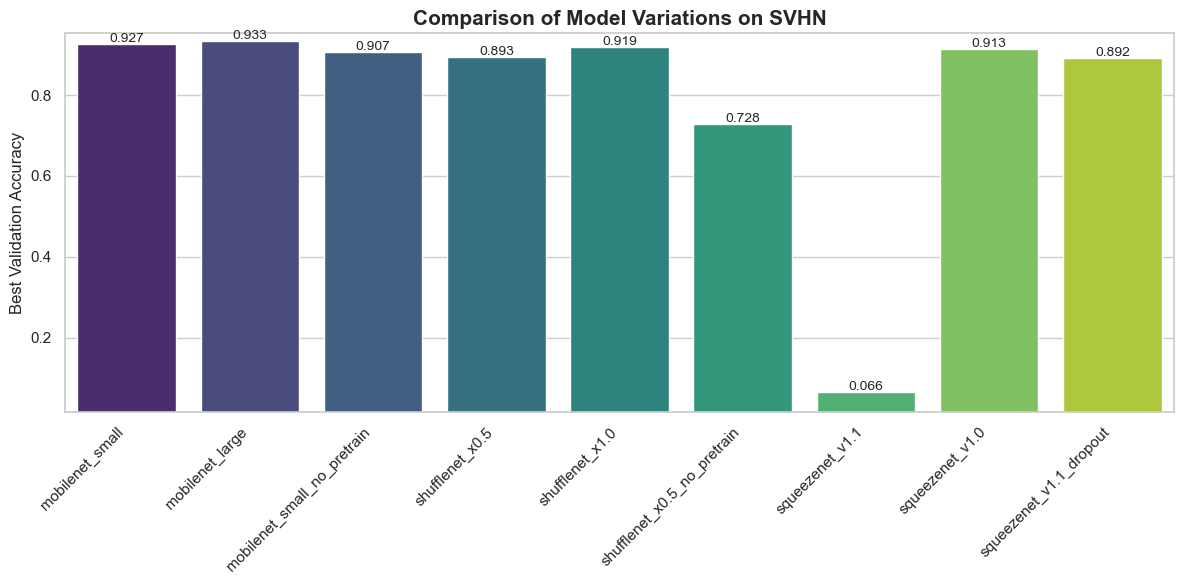


Results saved to 'svhn_model_comparison.csv'


In [33]:
import pandas as pd

# 1. Create a Comparison Table
stats_list = []
for name, data in results_log.items():
    stats_list.append({
        "Model Variation": name,
        "Best Val Accuracy": f"{data['best_val_acc']:.4f}",
        "Total Time (sec)": f"{data['duration']:.2f}",
        "Avg Time per Epoch": f"{(data['duration']/3):.2f}"
    })

df_results = pd.DataFrame(stats_list)
print("\n" + "="*20 + " FINAL PROJECT COMPARISON " + "="*20)
print(df_results)

# 2. Visualize Accuracy vs. Efficiency
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Plotting the best accuracy for each variation
names = list(results_log.keys())
accs = [data['best_val_acc'] for data in results_log.values()]

ax = sns.barplot(x=names, y=accs, palette="viridis")
plt.xticks(rotation=45, ha='right')
plt.title("Comparison of Model Variations on SVHN", fontsize=15, fontweight='bold')
plt.ylabel("Best Validation Accuracy")
plt.ylim(min(accs) - 0.05, max(accs) + 0.02) # Zoom in on the differences

# Add text labels on top of bars
for i, acc in enumerate(accs):
    ax.text(i, acc + 0.005, f'{acc:.3f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

# 3. Save results to a file for your report
df_results.to_csv("svhn_model_comparison.csv", index=False)
print("\nResults saved to 'svhn_model_comparison.csv'")